In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold

from sklearn.metrics import auc
from sklearn.metrics import roc_auc_score

from matplotlib import pyplot as plt
%matplotlib inline

### Data preparation

In [2]:
# !wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

In [3]:
df = pd.read_csv("course_lead_scoring_2026.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [6]:
cat = list(df.columns[df.dtypes == 'str'])
num = list(df.columns[df.dtypes != 'str'])
num.remove('converted')
cat, num

(['lead_source', 'industry', 'employment_status', 'location'],
 ['annual_income',
  'number_of_courses_viewed',
  'interaction_count',
  'lead_score'])

In [7]:
df[cat] = df[cat].fillna('NA')
df[num] = df[num].fillna(0.0)

In [8]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

y_train = df_train.converted.values
y_val = df_val.converted.values

del df_train['converted']
del df_val['converted']

In [9]:
df_full_train.shape, df_train.shape, df_val.shape, df_test.shape

((4000, 9), (3000, 8), (1000, 8), (1000, 9))

### 1. ROC AUC feature importance

In [10]:
for col in num:
    roc_auc = roc_auc_score(y_train, df_train[col])
    print('%s: %f' % (col, roc_auc))

annual_income: 0.608198
number_of_courses_viewed: 0.722989
interaction_count: 0.764920
lead_score: 0.788225


### 2. Model AUC

In [11]:
def get_dict(df):
    return df[cat + num].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

In [12]:
train_dict = get_dict(df_train)
X_train = dv.fit_transform(train_dict)

model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [13]:
val_dict = get_dict(df_val)
X_val = dv.transform(val_dict)
y_pred = model.predict_proba(X_val)[:, 1]

In [14]:
auc = roc_auc_score(y_val, y_pred)
auc = round(auc, 3)
auc

0.732

### 3. Precision and recall

In [15]:
thresholds = np.linspace(0.0, 1.0, 101)
thresholds

array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
       0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
       0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
       0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
       0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
       0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64, 0.65,
       0.66, 0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75, 0.76,
       0.77, 0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87,
       0.88, 0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98,
       0.99, 1.  ])

In [16]:
scores = []

for t in thresholds:
    tp = ((y_pred >= t) & (y_val == 1)).sum()
    fp = ((y_pred >= t) & (y_val == 0)).sum()
    tn = ((y_pred < t) & (y_val == 0)).sum()
    fn = ((y_pred < t) & (y_val == 1)).sum()

    precision = tp / (tp + fp) if tp + fp != 0 else np.nan
    recall = tp / (tp + fn) if tp + fn != 0 else np.nan

    scores.append((t, tp, fp, fn, tn, precision, recall))

df_scores = pd.DataFrame(scores)
df_scores.columns = ['threshold', 'tp', 'fp', 'fn', 'tn', 'precision', 'recall']

In [17]:
df_scores[::10]

,threshold,tp,fp,fn,tn,precision,recall
0,0.0,586,414,0,0,0.586000,1.000000
10,0.1,586,414,0,0,0.586000,1.000000
20,0.2,586,414,0,0,0.586000,1.000000
30,0.3,586,403,0,11,0.592518,1.000000
40,0.4,573,362,13,52,0.612834,0.977816
50,0.5,531,294,55,120,0.643636,0.906143
60,0.6,457,190,129,224,0.706337,0.779863
70,0.7,311,82,275,332,0.791349,0.530717
80,0.8,139,23,447,391,0.858025,0.237201
90,0.9,19,1,567,413,0.950000,0.032423


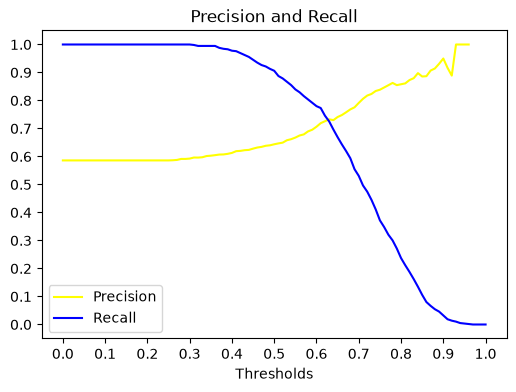

In [18]:
plt.figure(figsize=(6, 4))

plt.plot(df_scores.threshold, df_scores.precision, color='yellow', linestyle='solid', label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, color='blue', linestyle='solid', label='Recall')
plt.legend()

plt.xticks(np.linspace(0, 1, 11))
plt.yticks(np.linspace(0, 1, 11))

plt.xlabel('Thresholds')
plt.title('Precision and Recall')

plt.show()

In [19]:
df_scores['diff'] = abs(df_scores.precision - df_scores.recall)
df_scores[['threshold', 'diff']]

,threshold,diff
0,0.00,0.414000
1,0.01,0.414000
2,0.02,0.414000
3,0.03,0.414000
4,0.04,0.414000
...,...,...
96,0.96,0.998294
97,0.97,NaN
98,0.98,NaN
99,0.99,NaN


In [20]:
df_scores[['threshold', 'diff']].sort_values(by='diff').head(5)

,threshold,diff
63,0.63,0.007503
62,0.62,0.019820
64,0.64,0.033629
61,0.61,0.053990
65,0.65,0.072079


### 4. F1 score

In [21]:
df_scores['f1'] = 2 * df_scores.precision * df_scores.recall / (df_scores.precision + df_scores.recall)
df_scores['f1']

0      0.738966
1      0.738966
2      0.738966
3      0.738966
4      0.738966
         ...   
96     0.003407
97          NaN
98          NaN
99          NaN
100         NaN
Name: f1, Length: 101, dtype: float64

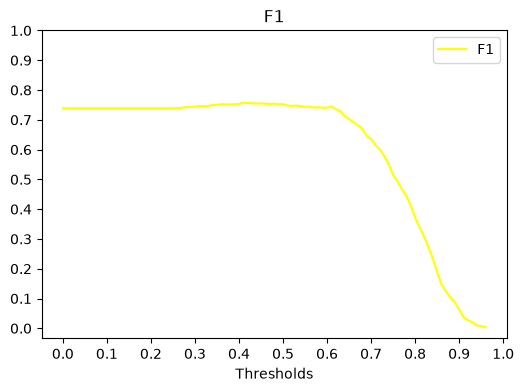

In [22]:
plt.figure(figsize=(6, 4))

plt.plot(df_scores.threshold, df_scores.f1, color='yellow', linestyle='solid', label='F1')
plt.legend()

plt.xticks(np.linspace(0, 1, 11))
plt.yticks(np.linspace(0, 1, 11))

plt.xlabel('Thresholds')
plt.title('F1')

plt.show()

In [23]:
df_scores[['threshold', 'f1']].sort_values(by='f1', ascending=False).head(5)

,threshold,f1
41,0.41,0.757616
42,0.42,0.756325
43,0.43,0.756032
45,0.45,0.754768
44,0.44,0.754717


### 5. 5-Fold CV standard deviation

In [24]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [25]:
def train(df, y):
    cat = get_dict(df)
    
    dv = DictVectorizer(sparse=False)
    dv.fit(cat)

    X = dv.transform(cat)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X, y)

    return dv, model


def predict(df, dv, model):
    cat = get_dict(df)
    
    X = dv.transform(cat)

    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [26]:
aucs = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    y_train = df_train.converted.values

    df_val = df_full_train.iloc[val_idx]
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    roc_auc = roc_auc_score(y_val, y_pred)
    aucs.append(roc_auc)

In [27]:
np.array(aucs).round(3)

array([0.731, 0.73 , 0.736, 0.741, 0.721])

In [28]:
print('std = %0.3f' % np.std(aucs))

std = 0.007


### 6. Best C

In [29]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [30]:
def train(df, y, C=1.0):
    cat = get_dict(df)
    
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(cat)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y)

    return dv, model


def predict(df, dv, model):
    cat = get_dict(df)
    
    X = dv.transform(cat)

    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [31]:
C = [0.000001, 0.001, 1]

for c in C:
    aucs = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        y_train = df_train.converted.values
        
        df_val = df_full_train.iloc[val_idx]       
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=c)
        y_pred = predict(df_val, dv, model)
        
        auc = roc_auc_score(y_val, y_pred)
        aucs.append(auc)

    print('C=%s, auc = %0.3f ± %0.3f' % (c, np.mean(aucs), np.std(aucs)))

C=1e-06, auc = 0.617 ± 0.019
C=0.001, auc = 0.749 ± 0.010
C=1, auc = 0.732 ± 0.007
